In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

# Go one level up from the current working directory
ROOT_DIR = os.path.dirname(os.getcwd())

#Build Path
DATA_DIR = os.path.join(ROOT_DIR, "data", "raw")

# Load datasets
train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
#test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

In [ ]:
train.head()

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
0,200,M,Shlok,paid,Johnson,1749042,1538352001000,Logged In,NextSong,22683,"Dallas-Fort Worth-Arlington, TX",278,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,524.32934,Ich mache einen Spiegel - Dream Part 4,Popol Vuh,2018-10-01 00:00:01,2018-08-08 13:22:21
992,200,M,Shlok,paid,Johnson,1749042,1538352525000,Logged In,NextSong,22683,"Dallas-Fort Worth-Arlington, TX",279,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,178.02404,Monster (Album Version),Skillet,2018-10-01 00:08:45,2018-08-08 13:22:21
1360,200,M,Shlok,paid,Johnson,1749042,1538352703000,Logged In,NextSong,22683,"Dallas-Fort Worth-Arlington, TX",280,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,232.61995,Seven Nation Army,The White Stripes,2018-10-01 00:11:43,2018-08-08 13:22:21
1825,200,M,Shlok,paid,Johnson,1749042,1538352935000,Logged In,NextSong,22683,"Dallas-Fort Worth-Arlington, TX",281,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,265.50812,Under The Bridge (Album Version),Red Hot Chili Peppers,2018-10-01 00:15:35,2018-08-08 13:22:21
2366,200,M,Shlok,paid,Johnson,1749042,1538353200000,Logged In,NextSong,22683,"Dallas-Fort Worth-Arlington, TX",282,"""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK...",PUT,471.69261,Circlesong 6,Bobby McFerrin,2018-10-01 00:20:00,2018-08-08 13:22:21


## Preprocessor 

### Feature engineering 

In [ ]:
# Both variables are binary and can be one-hot-encoded
train["gender"].value_counts(), train["level"].value_counts()

(gender
 M    9191364
 F    8308272
 Name: count, dtype: int64,
 level
 paid    13506659
 free     3992977
 Name: count, dtype: int64)

In [ ]:
from sklearn.preprocessing import OrdinalEncoder

# Gender One-Hot-Encoding
train['gender_encoded'] = OrdinalEncoder().fit_transform(train[["gender"]]).astype(int)
train = train.drop(columns=["gender"])

In [ ]:
# Subscription type One-Hot-Encoding
train['level_encoded'] = OrdinalEncoder().fit_transform(train[["level"]]).astype(int)
train = train.drop(columns=["level"])

In [ ]:
train["userAgent"].value_counts().sample()

userAgent
Mozilla/5.0 (Windows NT 5.1; rv:31.0) Gecko/20100101 Firefox/31.0    193892
Name: count, dtype: int64

In [ ]:
# OS extraction
train['os'] = train['userAgent'].str.extract(r'\(([^;)]+)')[0]

# Grouping all versions of Windows
train['os'] = train['os'].str.replace(r'Windows.*', 'Windows', regex=True)

# Same for browser
train['browser'] = train['userAgent'].str.extract(
    r'(Chrome|Firefox|Safari|Edge|Opera)'
)[0]

<Axes: xlabel='os'>

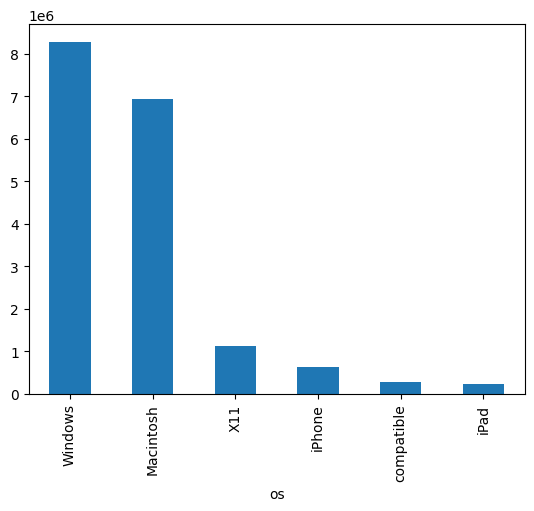

In [ ]:
train["os"].value_counts().plot(kind="bar")

<Axes: xlabel='browser'>

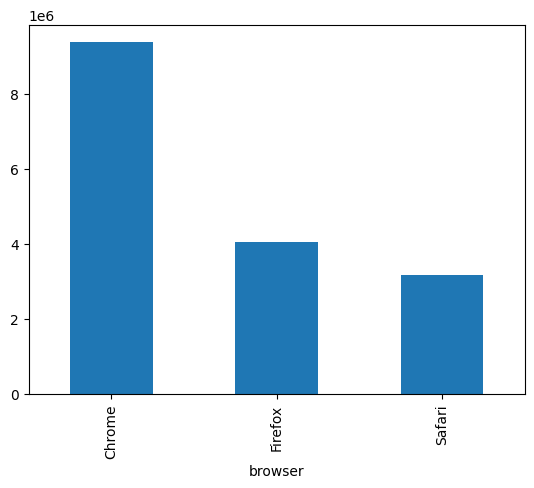

In [ ]:
train["browser"].value_counts().plot(kind="bar")

## 10-days Rolling Windows